In [ ]:
import statistics as st
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("autolevante_visitas.csv", sep=";")
#
nulos = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% del total": (df.isna().mean() * 100).round(1),
})

nulos[nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)

#Con esto podemos observar que la descripcion es un valor inutil ya que esta el 60 % del campo nulo
#Aparte de que no nos dice nada la descripcion
#Fecha de ultima revision es un tema a debate por su falta de contenido , pero su importancia
#Los Km y la gravedad podemos recrear esos datos usando la media , moda , etc..





,Nulos,% del total
descripcion_averia,960,60.0
fecha_ultima_revision,608,38.0
km,158,9.9
gravedad,16,1.0


In [ ]:
descripcion_averia = df["descripcion_averia"].dropna()
print(f"Hay descripcion en : {len(descripcion_averia)} de {len(df)}")

#Con esto sabemos a mayor exactitud

Hay descripcion en : 640 de 1600


In [ ]:
# Contamos cuántas veces sale cada matrícula
conteo = df["matricula"].value_counts()

# Creamos una tabla sencilla comparando Únicas vs Repetidas
resumen_matriculas = pd.DataFrame({
    "Grupo": ["No se repiten (1 vez)", "Se repiten (2 a 7 veces)", "TOTAL"],
    "Nº de matrículas": [
        (conteo == 1).sum(),
        (conteo > 1).sum(),
        df["matricula"].nunique()
    ],
    "Filas que ocupan en el CSV": [
        conteo[conteo == 1].sum(),
        conteo[conteo > 1].sum(),
        len(df)
    ]
})

resumen_matriculas["% de matrículas"] = (resumen_matriculas["Nº de matrículas"] / df["matricula"].nunique() * 100).round(1)
resumen_matriculas

,Grupo,Nº de matrículas,Filas que ocupan en el CSV,% de matrículas
0,No se repiten (1 vez),268,268,35.8
1,Se repiten (2 a 7 veces),480,1332,64.2
2,TOTAL,748,1600,100.0


In [ ]:
# 1. Quitamos espacios, ponemos solo la primera letra en mayúscula y pasamos 'N/d' a nulo (NaN)
df["combustible"] = (
    df["combustible"]
    .str.strip()                                 # 1. Quita espacios al inicio y al final
    .str.lower()                                 # 2. Pasa todo a minúsculas
    .replace("n/d", np.nan)                      # 3. Convierte 'n/d' en nulo (NaN)
    .str.normalize("NFKD")                       # 4. Separa las letras de sus tildes
    .str.encode("ascii", errors="ignore")        # 5. Elimina las tildes
    .str.decode("utf-8")                         # 6. Devuelve el texto limpio en UTF-8
)

df["combustible"].value_counts(dropna=False)
df["combustible"].value_counts(dropna=False)




,count
combustible,
diesel,678
gasolina,548
hibrido,252
electrico,74
NaN,48


/tmp/ipykernel_2975/2153435282.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2975/2153435282.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


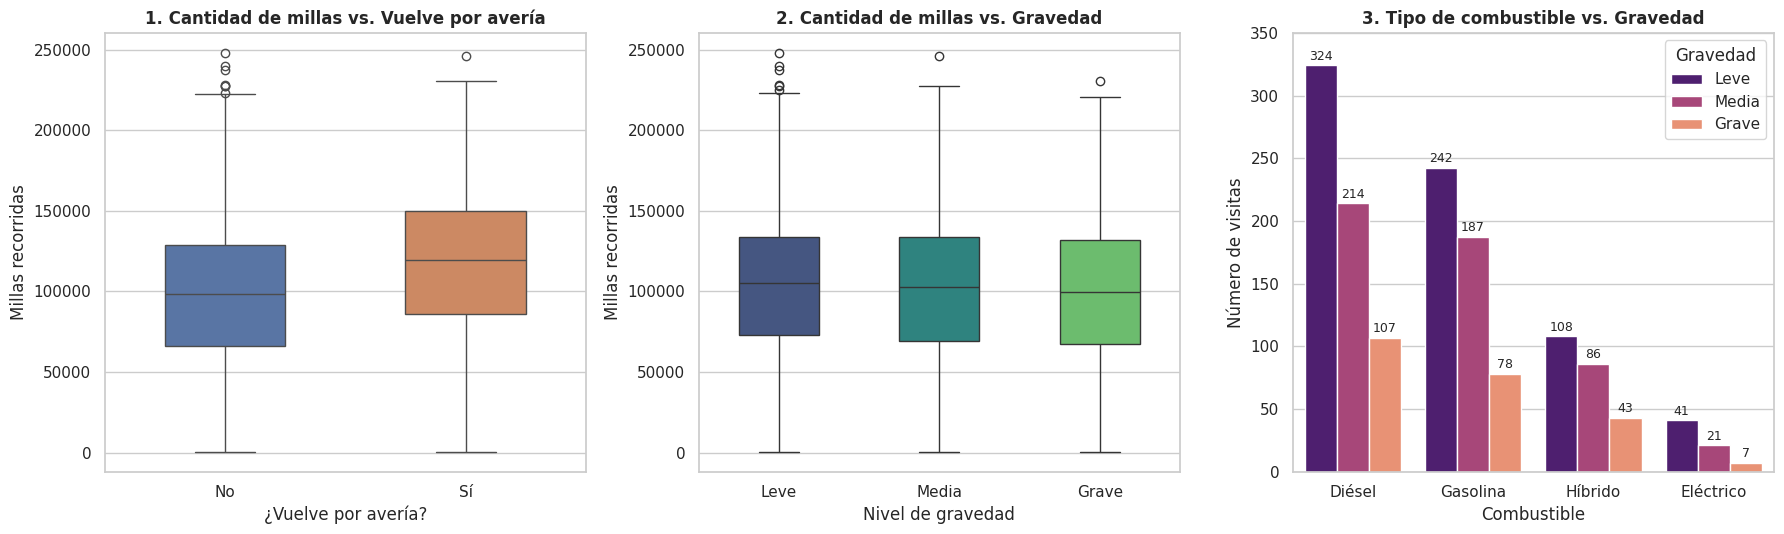

In [ ]:
# Configuración general de la figura (1 fila, 3 columnas)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

orden_gravedad = ["Leve", "Media", "Grave"]

# ---------------------------------------------------------
# 1. Cantidad de millas x Vuelve a avería (Boxplot)
# ---------------------------------------------------------
sns.boxplot(
    data=df,
    x="vuelve_averia",
    y="millas",
    order=["No", "Sí"],
    palette=["#4C72B0", "#DD8452"],
    width=0.5,
    ax=axes[0]
)
axes[0].set_title("1. Cantidad de millas vs. Vuelve por avería", fontweight="bold")
axes[0].set_xlabel("¿Vuelve por avería?")
axes[0].set_ylabel("Millas recorridas")

# ---------------------------------------------------------
# 2. Cantidad de millas x Gravedad (Boxplot)
# ---------------------------------------------------------
sns.boxplot(
    data=df,
    x="gravedad",
    y="millas",
    order=orden_gravedad,
    palette="viridis",
    width=0.5,
    ax=axes[1]
)
axes[1].set_title("2. Cantidad de millas vs. Gravedad", fontweight="bold")
axes[1].set_xlabel("Nivel de gravedad")
axes[1].set_ylabel("Millas recorridas")

# ---------------------------------------------------------
# 3. Combustible x Gravedad (Countplot agrupado)
# ---------------------------------------------------------
sns.countplot(
    data=df,
    x="combustible",
    hue="gravedad",
    order=["Diésel", "Gasolina", "Híbrido", "Eléctrico"],
    hue_order=orden_gravedad,
    palette="magma",
    ax=axes[2]
)
axes[2].set_title("3. Tipo de combustible vs. Gravedad", fontweight="bold")
axes[2].set_xlabel("Combustible")
axes[2].set_ylabel("Número de visitas")
axes[2].legend(title="Gravedad")

# Añadir los números encima de cada barra en la 3ª gráfica
for container in axes[2].containers:
    axes[2].bar_label(container, fontsize=9, padding=2)
axes[2].set_ylim(0, 350)

plt.tight_layout()
plt.show()

Se puede ver bien representado arriba que el nivel de gravedad en funcion de las millas no es una biena relación , ya que las 3 cajas estan a la misma altura , en cambio cuando lo comparamos si vuelven por una avería , vemos claramente que los que vuelven tienen mas millas .


Y en la ultima se ve claramente que esta directamente relacionado el tipo de combistible con la gravedad de la reparación.


Tambien gracias a estos datos nos hemos podido dar cuenta de que el CSV no esta normalizado y faltan datos , sobre todo con el tipo de combustible.



In [ ]:
#from google.colab import files

# 1. Guardamos el DataFrame modificado en un nuevo archivo CSV
# Usamos index=False para que Pandas no añada una columna extra con los números de fila (0, 1, 2...)
#df.to_csv("autolevante_visitas_limpio.csv", sep=";", index=False, encoding="utf-8")

# 2. Forzamos la descarga directa a tu ordenador
#files.download("autolevante_visitas_limpio.csv")

df["combustible"]

#Como se puede ver hay muchisimos tipos de combistible :


,combustible
0,HÍBRIDO
1,Gasolina
2,Eléctrico
3,Híbrido
4,N/D
...,...
1595,DIÉSEL
1596,Gasolina
1597,Eléctrico
1598,Gasolina
